# 06 — CLV, Prioritization & ROI Simulation

**Inputs:** `telco_features_scored_latest.parquet` (Module 3). Optional, used only for sensitivity checks: `telco_survival_approximation_latest.parquet` (Module 4) and `telco_uplift_experimental_latest.parquet` (Module 5).

This notebook covers **Module 6** (CLV × risk prioritization) and **Module 7** (revenue-at-risk and ROI simulation) of the proposal in one place, as laid out in the repository structure. It is part of the **core system**: unlike Modules 4 and 5, it does not depend on any future-work output.

**The question it answers** (proposal Section 2): *given a limited marketing budget, which customers should we target, and how much revenue can we realistically save?*

**Scope of this notebook**
1. Obtain honest (out-of-fold) churn probabilities
2. State the business assumptions the data cannot supply
3. Estimate customer lifetime value (CLV), and test how much the CLV method matters
4. Size the revenue and value at risk
5. Derive the expected net value of contacting each customer, including a closed-form break-even risk
6. Build the CLV × risk prioritization matrix
7. Simulate campaigns: profit curves, profit-optimal vs. accuracy/F1-optimal thresholds, business KPIs, break-even save rates, sensitivity, and a robust contact list
8. Persist a ranked target list and the assumptions behind it


## What This Module Can and Cannot Claim

**What it is built on.** Real customer data and Module 3's churn model, combined with **explicit business assumptions** that the IBM dataset cannot supply: profit margin, the cost and depth of an offer, how many would-be churners an offer actually saves, the CLV horizon, and the discount rate. Every one of these is a labeled placeholder in Section 3, not a finding.

**What it can claim**
- *Relative* statements: who should be prioritized, how much value-aware ranking adds over risk-only ranking, how profit-optimal thresholds differ from accuracy- or F1-optimal ones
- *Conditional* statements: "under these assumptions, the profit-optimal campaign contacts about X% of customers"
- The **shape** of the economics: how required save rates rise with campaign size, and which assumptions matter most

**What it cannot claim**
- Absolute dollar figures as forecasts. They scale directly with the assumptions (Section 8.5 shows profit moving by roughly a factor of 10 across plausible ranges)
- That an offer will save any particular share of churners. That number can only come from a randomized pilot (Module 5 sizes one)

**What it deliberately does not depend on.** The core path uses Modules 1–3 only. Module 4's survival model appears only as a CLV *sensitivity check*, and Module 5's simulated uplift appears only in an optional cross-tabulation.


In [1]:
import json
import warnings
from datetime import date
from itertools import product
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import spearmanr
from sklearn.calibration import CalibratedClassifierCV
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (accuracy_score, average_precision_score, brier_score_loss,
                             f1_score, roc_auc_score)
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 200)
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

FEATURE_STORE_DIR = Path("../data/feature_store")
CONFIGS_DIR = Path("../configs")
REPORTS_DIR = Path("../reports")
CONFIGS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)


## 2. Load Data and Obtain Out-of-Fold Churn Probabilities

In [2]:
df = pd.read_parquet(FEATURE_STORE_DIR / "telco_features_scored_latest.parquet")
n = len(df)
y = (df["Churn"] == "Yes").astype(int).to_numpy()
mc = df["MonthlyCharges"].to_numpy()
print(f"{n:,} customers | observed churn rate {y.mean():.4f} | mean monthly charges ${mc.mean():.2f}")
df[["customerID", "persona_name", "tenure", "MonthlyCharges", "churn_probability"]].head(3)


7,043 customers | observed churn rate 0.2654 | mean monthly charges $64.76


,customerID,persona_name,tenure,MonthlyCharges,churn_probability
0,7590-VHVEG,New & Price-Sensitive,1,29.85,0.640019
1,5575-GNVDE,New & Price-Sensitive,34,56.95,0.054867
2,3668-QPYBK,New & Price-Sensitive,2,53.85,0.405564


### 2.1 Why not simply use the Module 3 scores?

Module 3's scored dataset scores *every* customer with a model that was trained on 80% of them. For those customers the scores are **in-sample** and look sharper than they will on customers the model has never seen. Business totals built on over-sharp scores would overstate how well targeting works.

Here every customer is instead scored by a model that **never saw them**: 5-fold cross-fitting with the same preprocessing, XGBoost settings, and isotonic calibration as Module 3. (`n_jobs=1` is used for determinism.)


In [3]:
numeric_features = ["tenure", "MonthlyCharges", "services_count", "contract_risk_flag"]
categorical_features = [
    "gender", "SeniorCitizen", "Partner", "Dependents",
    "PhoneService", "MultipleLines", "InternetService",
    "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport",
    "StreamingTV", "StreamingMovies", "Contract", "PaperlessBilling", "PaymentMethod",
]
X_all = df[numeric_features + categorical_features]

p_oof = np.zeros(n)
for tr, te in StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED).split(X_all, y):
    pre = ColumnTransformer([
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore", drop="if_binary"), categorical_features),
    ])
    X_tr, X_te = pre.fit_transform(X_all.iloc[tr]), pre.transform(X_all.iloc[te])
    base = XGBClassifier(
        n_estimators=300, max_depth=4, learning_rate=0.05,
        scale_pos_weight=(y[tr] == 0).sum() / (y[tr] == 1).sum(),
        eval_metric="logloss", random_state=RANDOM_SEED, n_jobs=1,
    )
    calibrated = CalibratedClassifierCV(estimator=base, method="isotonic", cv=5).fit(X_tr, y[tr])
    p_oof[te] = calibrated.predict_proba(X_te)[:, 1]

p_m3 = df["churn_probability"].to_numpy()
comparison = pd.DataFrame({
    "ROC-AUC": [roc_auc_score(y, p_m3), roc_auc_score(y, p_oof)],
    "PR-AUC": [average_precision_score(y, p_m3), average_precision_score(y, p_oof)],
    "Brier score": [brier_score_loss(y, p_m3), brier_score_loss(y, p_oof)],
    "mean probability": [p_m3.mean(), p_oof.mean()],
    "share with p >= 0.5": [(p_m3 >= 0.5).mean(), (p_oof >= 0.5).mean()],
}, index=["Module 3 scores (partly in-sample)", "Out-of-fold scores (used below)"]).round(4)
print(f"Observed churn rate for reference: {y.mean():.4f}")
comparison


Observed churn rate for reference: 0.2654


,ROC-AUC,PR-AUC,Brier score,mean probability,share with p >= 0.5
Module 3 scores (partly in-sample),0.8933,0.7415,0.1168,0.2665,0.1966
Out-of-fold scores (used below),0.8412,0.6525,0.1367,0.2649,0.1778


The out-of-fold ROC-AUC matches Module 3's held-out result (about 0.84), while the all-customer Module 3 score looks markedly better because most of those customers were in its training set. The out-of-fold mean probability also lines up with the observed churn rate, confirming the calibration carries over. **All business calculations below use the out-of-fold probability**, referred to as `p`.


In [4]:
p = p_oof
df["churn_probability_oof"] = p


## 3. Business Assumptions

The dataset contains revenue but no costs, margins, offers, or offer outcomes. Everything in this table is therefore an **assumption** and is varied in the sensitivity analysis (Section 8.5) and the robustness analysis (Section 8.6). Replace these with SmartTel's real figures when they exist; the Module 8 dashboard will expose them as inputs.


In [5]:
BASE = dict(
    margin=0.40,          # contribution margin on MonthlyCharges
    horizon=24,           # months of future margin counted in CLV
    annual_disc=0.10,     # annual discount rate
    hazard_mult=1.0,      # scales long-run churn hazard of retained customers
    save_rate=0.22,       # share of would-be churners an offer retains
    contact_cost=5.0,     # fixed cost per contacted customer ($)
    discount_pct=0.10,    # discount given to contacted customers who remain
    discount_months=6,    # duration of that discount
)

assumptions = pd.DataFrame([
    ("margin", BASE["margin"], "Share of MonthlyCharges that is contribution margin", "0.20 \u2013 0.60"),
    ("horizon", BASE["horizon"], "Months of future margin counted in CLV (caps extrapolation)", "12 \u2013 36"),
    ("annual_disc", BASE["annual_disc"], "Annual discount rate applied to future margin", "0% \u2013 20%"),
    ("hazard_mult", BASE["hazard_mult"], "Multiplier on retained customers' long-run churn hazard (tests the time-scale issue below)", "0.5 \u2013 2.0"),
    ("save_rate", BASE["save_rate"], "Share of would-be churners an offer retains (matches Module 5's simulated mean; the real value is unknown until a pilot)", "10% \u2013 35%"),
    ("contact_cost", BASE["contact_cost"], "Fixed cost of contacting one customer ($); no fixed campaign overhead is modeled", "$2 \u2013 $20"),
    ("discount_pct", BASE["discount_pct"], "Discount granted to contacted customers who remain", "5% \u2013 20%"),
    ("discount_months", BASE["discount_months"], "Length of that discount (months)", "held fixed"),
], columns=["parameter", "base value", "meaning", "tested range"]).set_index("parameter")
assumptions


,base value,meaning,tested range
parameter,,,
margin,0.40,Share of MonthlyCharges that is contribution m...,0.20 – 0.60
horizon,24.00,Months of future margin counted in CLV (caps e...,12 – 36
annual_disc,0.10,Annual discount rate applied to future margin,0% – 20%
hazard_mult,1.00,Multiplier on retained customers' long-run chu...,0.5 – 2.0
save_rate,0.22,Share of would-be churners an offer retains (m...,10% – 35%
contact_cost,5.00,Fixed cost of contacting one customer ($); no ...,$2 – $20
discount_pct,0.10,Discount granted to contacted customers who re...,5% – 20%
discount_months,6.00,Length of that discount (months),held fixed


### The data has two time scales that cannot be reconciled

IBM documents `Churn` as customers who left "within the last month". Read literally, a 26.5% monthly churn rate implies a mean customer lifetime of under 4 months, yet observed tenure averages 32 months. Module 4 resolved this by treating tenure as the customer lifetime and `Churn` as the event. This module needs two different quantities and keeps them apart:

1. **Near-term churn risk `p`** is Module 3's (out-of-fold) probability, interpreted as the probability that the customer is lost in the campaign window the churn label represents. The proposal's revenue-at-risk formula uses it the same way.
2. **Long-run hazard of retained customers** is estimated from exposure (churners ÷ customer-months) by persona, and is used *only* to size the margin stream a saved customer goes on to generate.

Because the data cannot reconcile these two scales, **absolute dollar figures are scenario-conditional**. The `hazard_mult` assumption scales the long-run hazard so Section 8.5 can test how much the unresolved time scale matters.


## 4. Customer Lifetime Value

### 4.1 Long-run hazard by persona

A constant monthly churn hazard is estimated for each persona as `churners ÷ total customer-months of exposure`. This is the maximum-likelihood estimate under a constant-hazard model, and it makes proper use of both churned and still-active customers.

> **Why not "average observed tenure by segment"?**  Mean tenure measures how long customers have *been* here, not how long they *will* stay, so it is replaced with an exposure-based hazard, and the original is kept as a comparison in Section 4.3.


In [6]:
persona_stats = df.assign(churned=y).groupby("persona_name").agg(
    customers=("tenure", "size"),
    churners=("churned", "sum"),
    customer_months=("tenure", "sum"),
    mean_tenure=("tenure", "mean"),
)
persona_stats["monthly_hazard"] = persona_stats["churners"] / persona_stats["customer_months"]
persona_stats["P(still active after 24 months)"] = (1 - persona_stats["monthly_hazard"]) ** 24
persona_hazard_i = df["persona_name"].map(persona_stats["monthly_hazard"]).to_numpy()
persona_stats.round(4)


,customers,churners,customer_months,mean_tenure,monthly_hazard,P(still active after 24 months)
persona_name,,,,,,
Long-Tenure Low-Engagement,1552,113,48169,31.0367,0.0023,0.9452
Loyal Premium,1817,202,110018,60.5493,0.0018,0.9569
New & High-Risk,1555,716,38077,24.4868,0.0188,0.6341
New & Price-Sensitive,2119,838,31726,14.9722,0.0264,0.5260


**CLV formula (margin basis, finite horizon `H`, discounted):**

`CLV_i = margin × MonthlyCharges_i × Σ_{m=1..H} [ (1 − h_g) / (1 + r) ]^m`

where `h_g` is the persona's monthly hazard and `r` the monthly discount rate. The horizon cap keeps the estimate from being dominated by long extrapolations for low-hazard personas.


In [7]:
def clv_persona(P):
    h = np.clip(persona_hazard_i * P["hazard_mult"], 0, 0.99)
    r = (1 + P["annual_disc"]) ** (1 / 12) - 1
    q = (1 - h) / (1 + r)
    annuity = np.where(np.abs(1 - q) < 1e-12, P["horizon"], q * (1 - q ** P["horizon"]) / (1 - q))
    return P["margin"] * mc * annuity

def economics(P, V=None):
    # Expected net value of contacting each customer, and the break-even churn probability.
    V = clv_persona(P) if V is None else V
    D = P["discount_pct"] * mc * P["discount_months"]        # discount cost if the customer remains
    s = P["save_rate"]
    N = s * p * V - P["contact_cost"] - (1 - p + s * p) * D
    p_star = (P["contact_cost"] + D) / (s * V + (1 - s) * D)
    return V, N, p_star, D

V, N, p_star, D = economics(BASE)
df["clv"] = V

clv_by_persona = df.groupby("persona_name")["clv"].agg(["mean", "median"]).round(0)
print(f"Mean CLV (margin, {BASE['horizon']}-month horizon): ${V.mean():,.0f}")
clv_by_persona


Mean CLV (margin, 24-month horizon): $484


,mean,median
persona_name,,
Long-Tenure Low-Engagement,181.0,171.0
Loyal Premium,765.0,787.0
New & High-Risk,616.0,627.0
New & Price-Sensitive,370.0,358.0


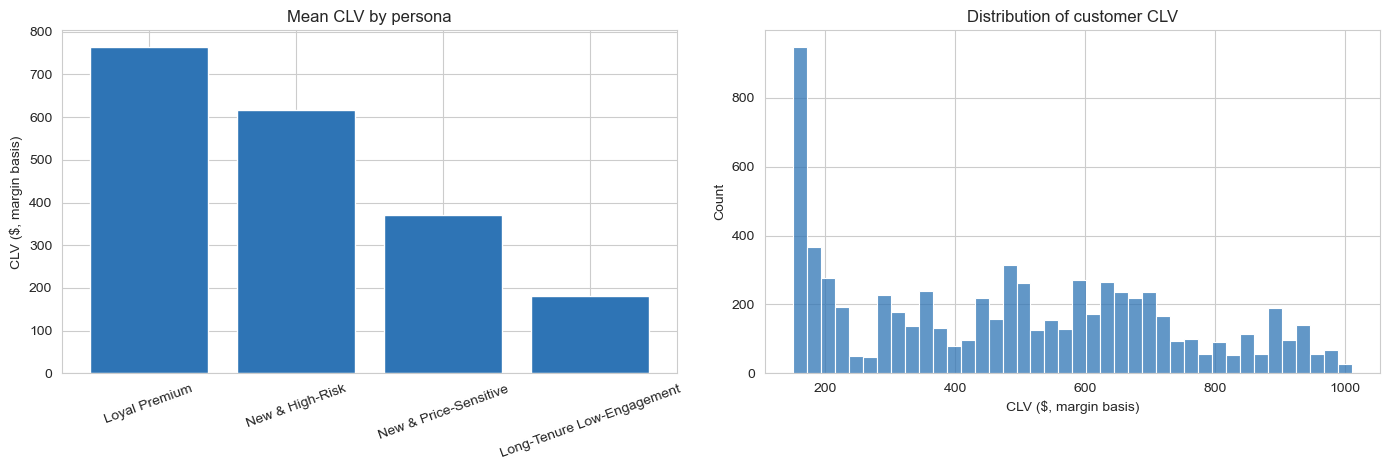

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
order = clv_by_persona["mean"].sort_values(ascending=False).index
axes[0].bar(order, clv_by_persona.loc[order, "mean"], color="#2E74B5")
axes[0].set_title("Mean CLV by persona")
axes[0].set_ylabel("CLV ($, margin basis)")
axes[0].tick_params(axis="x", rotation=20)
sns.histplot(V, bins=40, color="#2E74B5", ax=axes[1])
axes[1].set_title("Distribution of customer CLV")
axes[1].set_xlabel("CLV ($, margin basis)")
plt.tight_layout()
plt.show()


### 4.2 Why Module 4's median survival cannot serve as "remaining tenure"

Module 4 persisted `approx_predicted_median_survival_months`, and its summary suggested Module 6 might use it as a CLV input. **That does not work, and the earlier suggestion was a mistake.** It is the median *total* lifetime from signup for a given covariate profile. Subtracting a customer's current tenure does not give remaining life, because it ignores that the customer has already survived to today. The check below quantifies the problem.


In [9]:
survival_path = FEATURE_STORE_DIR / "telco_survival_approximation_latest.parquet"
if survival_path.exists():
    sv = df[["customerID", "tenure"]].merge(pd.read_parquet(survival_path), on="customerID")
    uncapped = sv[~sv["survival_estimate_censored_at_cap"]]
    naive_remaining = uncapped["approx_predicted_median_survival_months"] - uncapped["tenure"]
    print(f"Customers with a capped (unusable) estimate: {sv['survival_estimate_censored_at_cap'].mean() * 100:.1f}%")
    print(f"Among uncapped: predicted lifetime SHORTER than tenure already lived: {(naive_remaining < 0).mean() * 100:.1f}%")
else:
    print("Module 4 output not found; skipping this check.")


Customers with a capped (unusable) estimate: 39.7%
Among uncapped: predicted lifetime SHORTER than tenure already lived: 14.4%


The correct quantity is the **conditional** survival `S(t + u) / S(t)` of a customer who has already reached tenure `t`. It is computed below directly from a Cox model refit on Module 4's covariates. Beyond the longest observed tenure (72 months) the baseline hazard is extrapolated using the average increment over the last 12 observed months, an explicit assumption. This customer-specific CLV is used **only as a sensitivity check**, since Module 4 is an approximation (proposal Section 15) and the core path should not depend on it.


In [10]:
def cox_conditional_clv(P):
    from lifelines import CoxPHFitter
    cox_numeric = ["MonthlyCharges", "services_count", "contract_risk_flag"]
    cox_X = pd.get_dummies(df[cox_numeric + categorical_features], columns=categorical_features, drop_first=True)
    bool_cols = cox_X.select_dtypes(include="bool").columns
    cox_X[bool_cols] = cox_X[bool_cols].astype(int)
    fit_df = cox_X.assign(duration=df["tenure"].to_numpy(), event=y)

    cph = CoxPHFitter(penalizer=0.01).fit(fit_df, duration_col="duration", event_col="event")
    partial_hazard = cph.predict_partial_hazard(cox_X).to_numpy()

    H0 = cph.baseline_cumulative_hazard_.iloc[:, 0]
    horizon = P["horizon"]
    grid = np.arange(0, int(df["tenure"].max()) + horizon + 1)
    H0_grid = np.interp(grid, H0.index.to_numpy(), H0.to_numpy(), left=0.0)
    last = int(H0.index.max())
    slope = (H0.iloc[-1] - H0[H0.index <= last - 12].iloc[-1]) / 12      # average increment, last 12 months
    H0_grid[grid > last] = H0.iloc[-1] + slope * (grid[grid > last] - last)

    t = df["tenure"].to_numpy().astype(int)
    idx = t[:, None] + np.arange(1, horizon + 1)[None, :]
    cumulative = H0_grid[idx] - H0_grid[t][:, None]
    survival = np.exp(-partial_hazard[:, None] * cumulative)               # S(t+u | x) / S(t | x)
    r = (1 + P["annual_disc"]) ** (1 / 12) - 1
    discount = (1 + r) ** -np.arange(1, horizon + 1)
    return P["margin"] * mc * (survival * discount).sum(axis=1)

try:
    V_cox = cox_conditional_clv(BASE)
    print(f"Mean CLV: persona-hazard ${V.mean():,.0f} | Cox conditional ${V_cox.mean():,.0f}")
except ImportError:
    V_cox = None
    print("lifelines is not installed; skipping the Cox-conditional CLV variant.")


Mean CLV: persona-hazard $484 | Cox conditional $450


### 4.3 How much does the CLV method matter?

Four ways of valuing a customer are compared. Each is turned into an expected net contact value under the *same* economics, and compared on **who would be targeted** (rank agreement and overlap of the top-20% lists) and on **how many dollars it claims**. The last two columns evaluate each method's top-20% list under a common set of economics, which isolates the effect of the *ranking* from the effect of the *dollar scale*.


In [11]:
persona_mean_tenure = df["persona_name"].map(df.groupby("persona_name")["tenure"].mean()).to_numpy()
methods = {
    "Persona hazard (primary)": V,
    "Mean tenure x charges (proposal baseline)": BASE["margin"] * mc * np.minimum(persona_mean_tenure, BASE["horizon"]),
    "No lifetime (flat horizon revenue)": BASE["margin"] * mc * BASE["horizon"],
}
if V_cox is not None:
    methods["Cox conditional (customer-specific)"] = V_cox

net_by_method = {name: economics(BASE, V=v)[1] for name, v in methods.items()}
k20 = int(0.20 * n)
top20 = {name: set(np.argsort(-nv)[:k20]) for name, nv in net_by_method.items()}
primary = "Persona hazard (primary)"

rows = []
for name, v in methods.items():
    row = {
        "mean CLV ($)": v.mean(),
        "rank corr. of CLV with primary": spearmanr(V, v).correlation,
        "top-20% overlap with primary": len(top20[name] & top20[primary]) / len(top20[name] | top20[primary]),
        "max profit claimed ($)": np.clip(net_by_method[name], 0, None).sum(),
        "top-20% profit, primary economics ($)": net_by_method[primary][list(top20[name])].sum(),
    }
    if V_cox is not None:
        row["top-20% profit, Cox economics ($)"] = net_by_method["Cox conditional (customer-specific)"][list(top20[name])].sum()
    rows.append(row)

method_comparison = pd.DataFrame(rows, index=list(methods)).round(3)
method_comparison


,mean CLV ($),rank corr. of CLV with primary,top-20% overlap with primary,max profit claimed ($),"top-20% profit, primary economics ($)","top-20% profit, Cox economics ($)"
Persona hazard (primary),484.445,1.000,1.000,81814.255,73515.236,57532.634
Mean tenure x charges (proposal baseline),558.921,0.982,0.798,113075.564,71876.394,56443.754
No lifetime (flat horizon revenue),621.712,0.974,0.907,147089.076,73134.074,58161.559
Cox conditional (customer-specific),449.909,0.896,0.788,65053.975,71176.712,60611.771


he persona hazard (primary) method produces a mean CLV of $484.45 and serves as the reference, while the proposal baseline (mean tenure × charges) achieves a high rank correlation of 0.982 but only 79.8% overlap in the top 20% of customers. The flat-horizon revenue method has the highest mean CLV ($621.71) and maximum claimed profit ($147,089.08), but this does not translate into the highest top-20% profit under either the primary or Cox economics assumptions. The customer-specific Cox method produces the lowest mean CLV ($449.91) and a lower top-20% overlap of 78.8%, yet achieves the highest top-20% profit under Cox economics ($60,611.77)

So **who to prioritize is fairly insensitive to the CLV method, while how many dollars a campaign will earn is not**, which is why dollar figures in this notebook always come with sensitivity analysis. The Cox variant's lower value also suggests the persona-hazard base case may be somewhat optimistic; Section 8.5 tests a doubled hazard.


## 5. Revenue and Value at Risk

Two measures are reported. **Monthly revenue at risk** is the proposal's formula, `Σ MonthlyCharges × p`. **Expected value at risk** is `Σ p × CLV`, the margin-basis value of the future stream that would be lost.


In [12]:
revenue_at_risk = mc * p
expected_value_at_risk = p * V

print(f"Total monthly revenue:                     ${mc.sum():>12,.0f}")
print(f"Monthly revenue at risk (sum charges x p): ${revenue_at_risk.sum():>12,.0f}  ({100 * revenue_at_risk.sum() / mc.sum():.1f}% of revenue)")
print(f"Expected value at risk (sum p x CLV):      ${expected_value_at_risk.sum():>12,.0f}")

persona_risk = df.assign(rar=revenue_at_risk, evar=expected_value_at_risk).groupby("persona_name").agg(
    customers=("tenure", "size"),
    monthly_revenue=("MonthlyCharges", "sum"),
    monthly_revenue_at_risk=("rar", "sum"),
    expected_value_at_risk=("evar", "sum"),
)
persona_risk["% of persona revenue at risk"] = 100 * persona_risk["monthly_revenue_at_risk"] / persona_risk["monthly_revenue"]
persona_risk["share of total expected value at risk (%)"] = 100 * persona_risk["expected_value_at_risk"] / persona_risk["expected_value_at_risk"].sum()
persona_risk.round(1)


Total monthly revenue:                     $     456,117
Monthly revenue at risk (sum charges x p): $     137,648  (30.2% of revenue)
Expected value at risk (sum p x CLV):      $     967,285


,customers,monthly_revenue,monthly_revenue_at_risk,expected_value_at_risk,% of persona revenue at risk,share of total expected value at risk (%)
persona_name,,,,,,
Long-Tenure Low-Engagement,1552,33161.4,2672.1,22613.4,8.1,2.3
Loyal Premium,1817,163170.5,21112.8,179770.2,12.9,18.6
New & High-Risk,1555,137318.9,62631.8,436931.3,45.6,45.2
New & Price-Sensitive,2119,122465.8,51231.2,327970.2,41.8,33.9


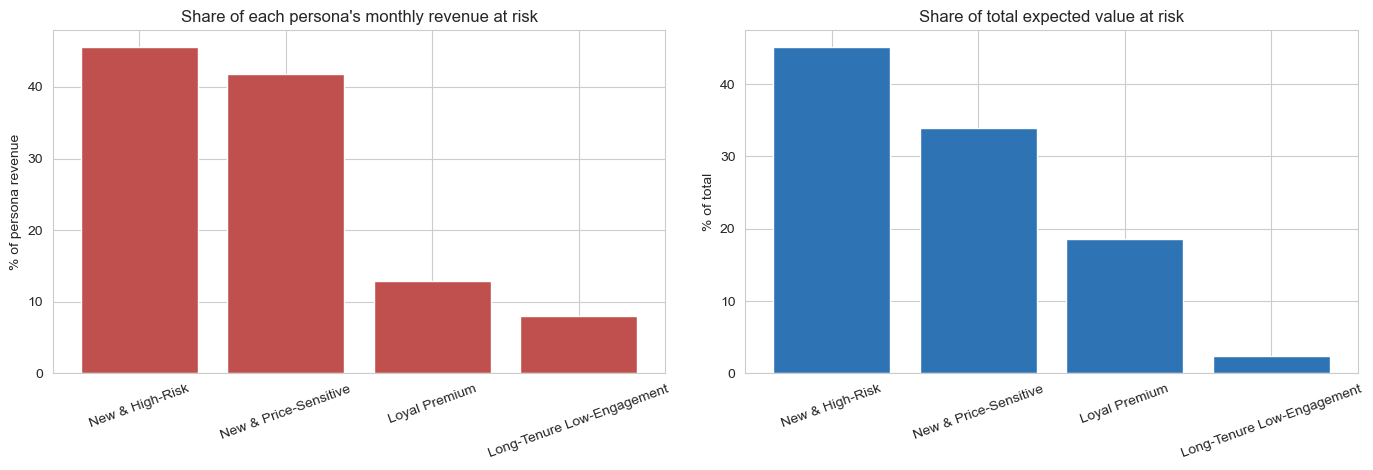

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
order = persona_risk["share of total expected value at risk (%)"].sort_values(ascending=False).index
axes[0].bar(order, persona_risk.loc[order, "% of persona revenue at risk"], color="#C0504D")
axes[0].set_title("Share of each persona's monthly revenue at risk")
axes[0].set_ylabel("% of persona revenue")
axes[0].tick_params(axis="x", rotation=20)
axes[1].bar(order, persona_risk.loc[order, "share of total expected value at risk (%)"], color="#2E74B5")
axes[1].set_title("Share of total expected value at risk")
axes[1].set_ylabel("% of total")
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()


The persona-level revenue-at-risk analysis shows that New & High-Risk customers represent the largest retention concern, contributing 45.2% of total expected value at risk. This segment has 1,555 customers, monthly revenue of $137,318.90, and expected value at risk of $436,931.30, with 45.6% of its persona revenue at risk. 

New & Price-Sensitive customers are the second-largest concern, accounting for 33.9% of total expected value at risk and placing 41.8% of their persona revenue at risk. Together, these two newer customer segments account for 79.1% of total expected value at risk, making them the primary candidates for targeted retention strategies. 

Loyal Premium customers contribute 18.6% of expected value at risk despite generating the highest monthly revenue ($163,170.50), suggesting that targeted loyalty interventions may help protect valuable recurring revenue. 

In contrast, Long-Tenure Low-Engagement customers account for only 2.3% of total expected value at risk, with 8.1% of their persona revenue at risk. Overall, the findings support prioritizing retention efforts toward newer, higher-risk and price-sensitive customers, while interpreting the estimates as model-based projections rather than guaranteed revenue losses.

## 6. The Economics of Contacting One Customer

Contacting customer *i* costs a fixed contact fee. If the offer works the customer stays and keeps generating margin; every contacted customer who **remains** also receives the discount (a conservative assumption, since it includes customers who would have stayed anyway). With `s` the save rate, `V` the CLV, and `D = discount% × MonthlyCharges × discount months` the discount cost:

`expected net value  N = s·p·V  −  contact cost  −  (1 − p + s·p)·D`

The three terms are the value of customers saved, the contact fee, and the discount paid to the customers who stay. Setting `N > 0` and solving gives a **closed-form break-even churn probability**:

`p* = (contact cost + D) / (s·V + (1 − s)·D)`

Contacting a customer pays off exactly when their churn probability exceeds `p*`. Because `V` and `D` differ by customer, **the threshold is value-aware**: it is lower for high-value customers.


In [14]:
assert np.array_equal(N > 0, p > p_star), "closed-form break-even disagrees with direct calculation"

print(f"Customers worth contacting under base-case assumptions: {(N > 0).sum():,} ({100 * (N > 0).mean():.1f}%)")
print(f"Break-even churn probability p*: median {np.median(p_star):.3f}, "
      f"10th-90th percentile {np.quantile(p_star, 0.1):.3f}\u2013{np.quantile(p_star, 0.9):.3f}")


Customers worth contacting under base-case assumptions: 2,347 (33.3%)
Break-even churn probability p*: median 0.343, 10th-90th percentile 0.278–0.373


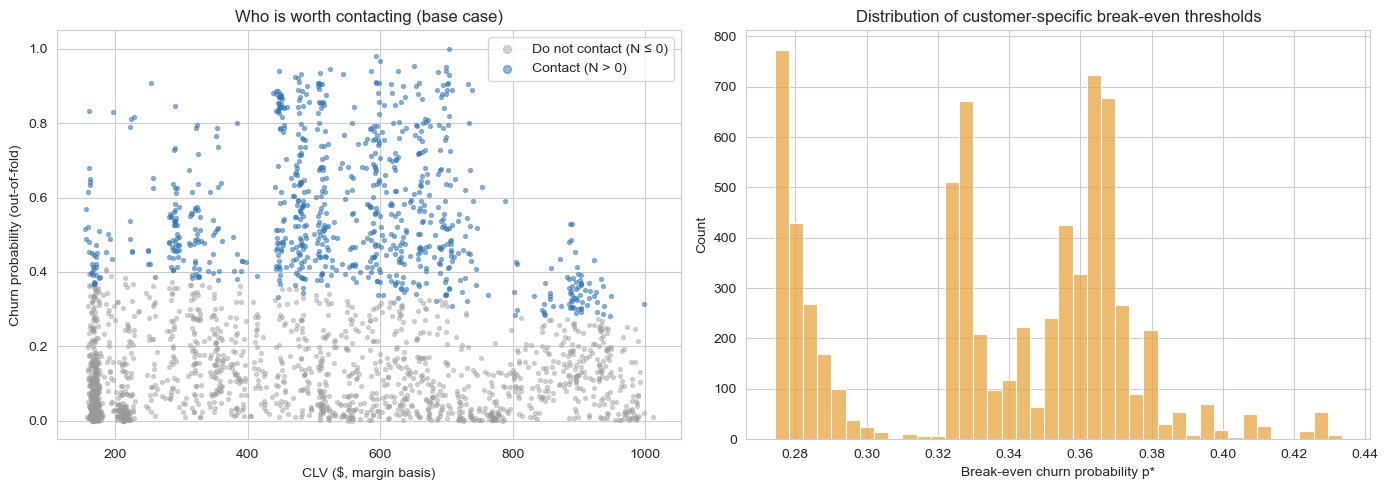

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
rng = np.random.default_rng(RANDOM_SEED)
sample = rng.choice(n, size=2500, replace=False)
worth = N[sample] > 0
axes[0].scatter(V[sample][~worth], p[sample][~worth], s=8, alpha=0.4, color="#999999", label="Do not contact (N \u2264 0)")
axes[0].scatter(V[sample][worth], p[sample][worth], s=8, alpha=0.5, color="#2E74B5", label="Contact (N > 0)")
axes[0].set_xlabel("CLV ($, margin basis)")
axes[0].set_ylabel("Churn probability (out-of-fold)")
axes[0].set_title("Who is worth contacting (base case)")
axes[0].legend(markerscale=2)

sns.histplot(p_star, bins=40, color="#E8A33D", ax=axes[1])
axes[1].set_xlabel("Break-even churn probability p*")
axes[1].set_title("Distribution of customer-specific break-even thresholds")
plt.tight_layout()
plt.show()


The decision boundary is nearly horizontal in the left panel: with these assumptions, **churn risk dominates the decision** and value shifts the threshold only modestly. That is an important property of this economic model, and Section 8.1 quantifies how little value-awareness adds over risk alone.


## 7. The CLV × Risk Prioritization Matrix

Customers are placed in a 3 × 3 grid for communication with stakeholders. **Value tiers** are terciles of CLV. **Risk tiers** use fixed, interpretable probability cut-offs: *High* (≥ 0.50, more likely than not to churn), *Medium* (0.20–0.50), *Low* (< 0.20). The matrix is **descriptive**; the decision rule that determines whom to contact is the economic one in Section 6, and the table below shows how closely the two agree.


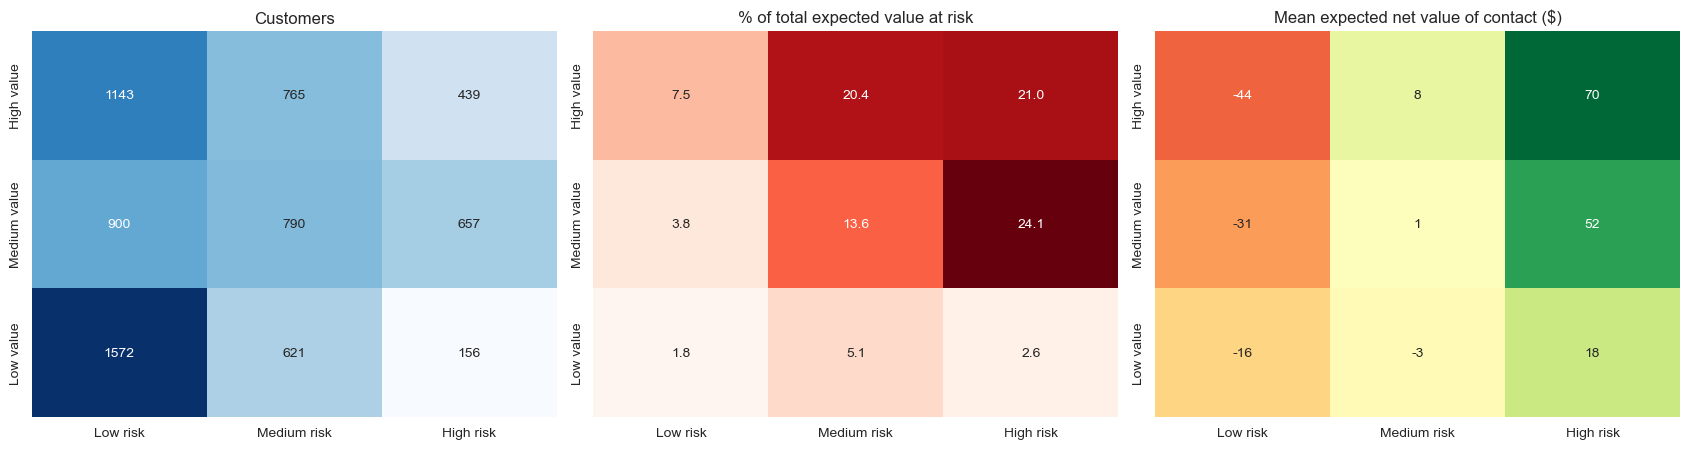

Share of each cell that the economic rule says to contact (%):


risk_tier,Low risk,Medium risk,High risk
value_tier,,,
High value,0.0,65.0,100.0
Medium value,0.0,50.4,100.0
Low value,0.0,32.2,100.0


In [16]:
value_tier = pd.qcut(V, 3, labels=["Low value", "Medium value", "High value"])
risk_tier = pd.cut(p, [-0.001, 0.20, 0.50, 1.001], labels=["Low risk", "Medium risk", "High risk"])

grid = pd.DataFrame({"value_tier": value_tier, "risk_tier": risk_tier,
                     "evar": expected_value_at_risk, "net": N, "contact": (N > 0).astype(float)})
row_order = ["High value", "Medium value", "Low value"]

counts = pd.crosstab(grid["value_tier"], grid["risk_tier"]).loc[row_order]
evar_share = grid.pivot_table(index="value_tier", columns="risk_tier", values="evar", aggfunc="sum", observed=True).loc[row_order]
evar_share = 100 * evar_share / evar_share.to_numpy().sum()
mean_net = grid.pivot_table(index="value_tier", columns="risk_tier", values="net", aggfunc="mean", observed=True).loc[row_order]
contact_share = 100 * grid.pivot_table(index="value_tier", columns="risk_tier", values="contact", aggfunc="mean", observed=True).loc[row_order]

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
sns.heatmap(counts, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0])
axes[0].set_title("Customers")
sns.heatmap(evar_share, annot=True, fmt=".1f", cmap="Reds", cbar=False, ax=axes[1])
axes[1].set_title("% of total expected value at risk")
sns.heatmap(mean_net, annot=True, fmt=".0f", cmap="RdYlGn", center=0, cbar=False, ax=axes[2])
axes[2].set_title("Mean expected net value of contact ($)")
for ax in axes:
    ax.set_xlabel("")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

print("Share of each cell that the economic rule says to contact (%):")
contact_share.round(1)


The results suggest prioritizing high-risk customers, especially those with medium or high customer value, while avoiding costly interventions for low-risk segments. These recommendations depend on the assumptions used to estimate contact costs, retention benefits, and customer value

## 8. ROI Simulator

### 8.1 Targeting policies and profit curves

Five ways of choosing whom to contact are compared. For each, customers are ranked and the top *k* are contacted; the curve shows cumulative expected profit as the campaign grows. Profit is the model-implied expectation under the Section 3 assumptions, so the **net-value ranking is optimal for this objective by construction**. The informative part is the *size* of its advantage over simpler rules.


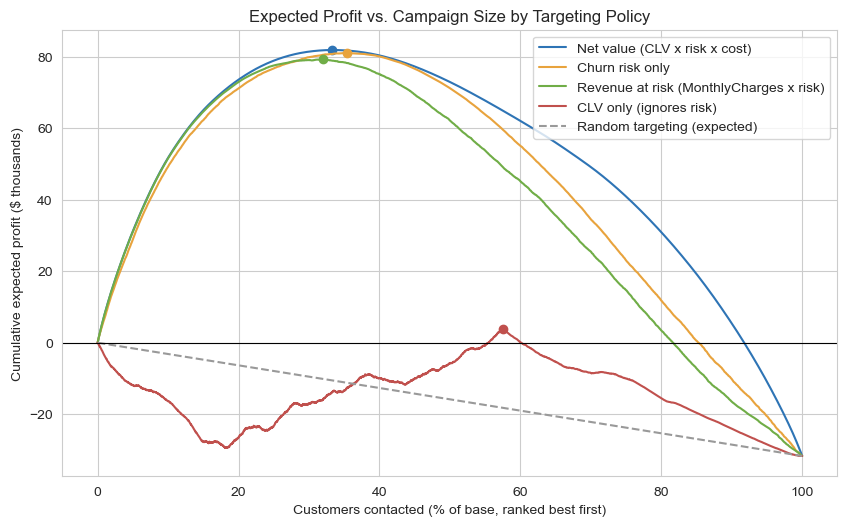

,optimal campaign (customers),optimal campaign (% of base),max profit ($),profit at 10% budget ($),profit at 20% budget ($),profit at 30% budget ($)
policy,,,,,,
Net value (CLV x risk x cost),2347,33.0,81814.0,51678.0,73515.0,81363.0
Churn risk only,2491,35.0,80980.0,49202.0,71090.0,79810.0
Revenue at risk (MonthlyCharges x risk),2254,32.0,79164.0,51508.0,72859.0,78987.0
CLV only (ignores risk),4056,58.0,3795.0,-16343.0,-26457.0,-17065.0
Random targeting (expected),0,0.0,-0.0,-3165.0,-6330.0,-9495.0


In [17]:
policies = {
    "Net value (CLV x risk x cost)": N,
    "Churn risk only": p,
    "Revenue at risk (MonthlyCharges x risk)": revenue_at_risk,
    "CLV only (ignores risk)": V,
}
curves = {name: np.concatenate([[0], np.cumsum(N[np.argsort(-score)])]) for name, score in policies.items()}
curves["Random targeting (expected)"] = np.arange(n + 1) * N.mean()

pct = 100 * np.arange(n + 1) / n
styles = {"Net value (CLV x risk x cost)": "#2E74B5", "Churn risk only": "#E8A33D",
          "Revenue at risk (MonthlyCharges x risk)": "#70AD47", "CLV only (ignores risk)": "#C0504D",
          "Random targeting (expected)": "#999999"}
fig, ax = plt.subplots(figsize=(10, 5.8))
for name, curve in curves.items():
    ax.plot(pct, curve / 1000, label=name, color=styles[name], linestyle="--" if name.startswith("Random") else "-")
    if not name.startswith("Random"):
        k = curve.argmax()
        ax.plot(pct[k], curve[k] / 1000, "o", color=styles[name])
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("Customers contacted (% of base, ranked best first)")
ax.set_ylabel("Cumulative expected profit ($ thousands)")
ax.set_title("Expected Profit vs. Campaign Size by Targeting Policy")
ax.legend()
plt.show()

rows = []
for name, curve in curves.items():
    k = int(curve.argmax())
    rows.append({"policy": name, "optimal campaign (customers)": k, "optimal campaign (% of base)": 100 * k / n,
                 "max profit ($)": curve[k], "profit at 10% budget ($)": curve[int(0.10 * n)],
                 "profit at 20% budget ($)": curve[int(0.20 * n)], "profit at 30% budget ($)": curve[int(0.30 * n)]})
policy_table = pd.DataFrame(rows).set_index("policy")
policy_table.round(0)


In [18]:
full = policy_table.loc["Net value (CLV x risk x cost)"]
for name in ["Churn risk only", "Revenue at risk (MonthlyCharges x risk)"]:
    r_ = policy_table.loc[name]
    print(f"{name}: {100 * r_['max profit ($)'] / full['max profit ($)']:.1f}% of the full model's max profit; "
          f"{100 * r_['profit at 20% budget ($)'] / full['profit at 20% budget ($)']:.1f}% at a 20% budget")
print(f"Full model gain over risk-only at a 10% budget: "
      f"{100 * (full['profit at 10% budget ($)'] / policy_table.loc['Churn risk only', 'profit at 10% budget ($)'] - 1):.1f}%")


Churn risk only: 99.0% of the full model's max profit; 96.7% at a 20% budget
Revenue at risk (MonthlyCharges x risk): 96.8% of the full model's max profit; 99.1% at a 20% budget
Full model gain over risk-only at a 10% budget: 5.0%


**What this shows.** Ranking by churn risk alone is already close to optimal. Adding CLV and cost information improves profit by only a few percent at fixed budgets up to about a 50% campaign, and by about one percent at the optimal campaign size. The simple `MonthlyCharges × risk` rule from the proposal captures nearly all of the full model's value. Ranking by **CLV alone** is the one clear mistake: valuable customers who are unlikely to leave are expensive to contact for little return, and it never earns meaningful profit.

Two further features of the curves are worth noting:
- **Contacting everyone loses money** (about $32k under these assumptions, the right-hand end of every curve). That is the basic case for targeting at all.
- **Value-aware ranking mainly protects against over-extending a campaign.** Its advantage over risk-only ranking is small at sensible sizes but grows quickly beyond the optimum (roughly 13% at a 60% budget and over 40% at 70%), because it steers spending away from low-value customers whose discounts are not worth paying.

This matches the pattern in Module 5, where churn risk was also hard to beat. For SmartTel the practical message is that **a good churn model carries most of the commercial value**; the CLV and cost layers refine it modestly, mainly by sizing the campaign and explaining decisions.


### 8.2 Profit-optimal vs. accuracy-optimal and F1-optimal thresholds

The proposal's claim is that the targeting threshold should maximize **expected profit**, not accuracy or F1. This section checks that claim directly. Accuracy and F1 are computed against the real churn labels using the out-of-fold probabilities; expected profit uses the economic model. The *value-aware* rule (contact if `N > 0`) uses a different threshold for each customer rather than one global cut-off.


In [19]:
thresholds = np.round(np.arange(0.02, 0.981, 0.01), 2)
scan = pd.DataFrame([{
    "threshold": t, "% contacted": 100 * (p >= t).mean(),
    "accuracy": accuracy_score(y, p >= t), "F1": f1_score(y, p >= t),
    "expected profit ($)": N[p >= t].sum(),
} for t in thresholds])

acc_opt = scan.loc[scan["accuracy"].idxmax()]
f1_opt = scan.loc[scan["F1"].idxmax()]
profit_opt = scan.loc[scan["expected profit ($)"].idxmax()]
default_05 = scan.loc[scan["threshold"] == 0.50].iloc[0]
value_aware = {"threshold": np.nan, "% contacted": 100 * (N > 0).mean(),
               "accuracy": accuracy_score(y, N > 0), "F1": f1_score(y, N > 0), "expected profit ($)": N[N > 0].sum()}

threshold_table = pd.DataFrame({
    "Default threshold 0.50": default_05, "Accuracy-optimal": acc_opt, "F1-optimal": f1_opt,
    "Profit-optimal (one global threshold)": profit_opt, "Value-aware (contact if N > 0)": pd.Series(value_aware),
}).T
threshold_table["profit vs. best (%)"] = 100 * (threshold_table["expected profit ($)"] / threshold_table["expected profit ($)"].max() - 1)
threshold_table.round(3)


,threshold,% contacted,accuracy,F1,expected profit ($),profit vs. best (%)
Default threshold 0.50,0.50,17.777,0.799,0.546,67864.096,-17.051
Accuracy-optimal,0.45,21.979,0.803,0.595,73734.228,-9.876
F1-optimal,0.30,37.953,0.759,0.626,80662.802,-1.407
Profit-optimal (one global threshold),0.32,35.411,0.768,0.625,80968.250,-1.034
Value-aware (contact if N > 0),NaN,33.324,0.769,0.614,81814.255,0.000


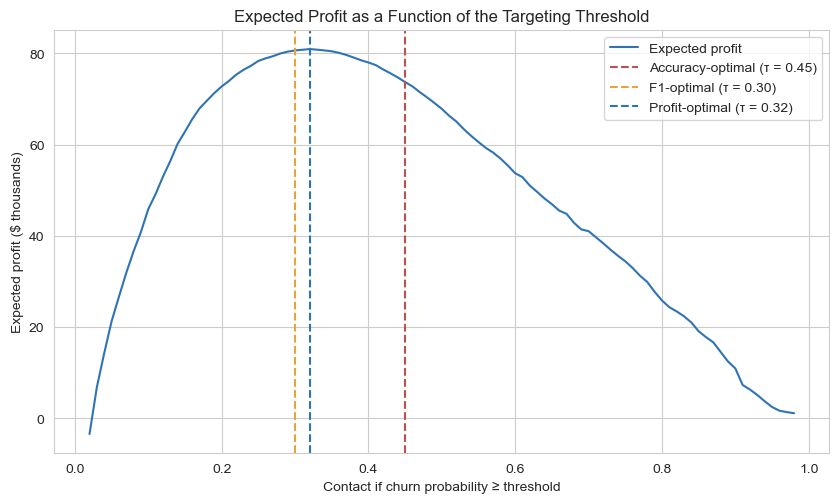

In [20]:
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(scan["threshold"], scan["expected profit ($)"] / 1000, color="#2E74B5", label="Expected profit")
for label, row, color in [("Accuracy-optimal", acc_opt, "#C0504D"), ("F1-optimal", f1_opt, "#E8A33D"),
                          ("Profit-optimal", profit_opt, "#2E74B5")]:
    ax.axvline(row["threshold"], color=color, linestyle="--", label=f"{label} (\u03C4 = {row['threshold']:.2f})")
ax.set_xlabel("Contact if churn probability \u2265 threshold")
ax.set_ylabel("Expected profit ($ thousands)")
ax.set_title("Expected Profit as a Function of the Targeting Threshold")
ax.legend()
plt.show()


The decision-threshold optimization curve demonstrates the commercial advantage of aligning model targeting thresholds with financial outcomes rather than standard classification accuracy. While an Accuracy-optimal threshold ($\tau = 0.45$) sets too strict a requirement and degrades expected profit to $\approx \$74,000$, setting the cutoff to the Profit-optimal threshold ($\tau = 0.32$) maximizes campaign returns at $\approx \$81,000$. Furthermore, the F1-optimal threshold ($\tau = 0.30$) closely mirrors the financial optimum (yielding $\approx \$80,500$), proving to be an effective statistical proxy. Consequently, implementing a probability decision boundary of $\tau = 0.32$ ensures that customer retention budgets are deployed at maximum net profitability without under-intervention.  

In [21]:
save_rates = [0.10, 0.22, 0.35]
discounts = [0.05, 0.10, 0.20]
tau_rows, best_rows, f1_rows = [], [], []
for s_ in save_rates:
    tau_row, best_row, f1_row = {}, {}, {}
    for d_ in discounts:
        N_ = economics({**BASE, "save_rate": s_, "discount_pct": d_})[1]
        profits = np.array([N_[p >= t].sum() for t in thresholds])
        key = f"discount {int(d_ * 100)}%"
        tau_row[key] = thresholds[profits.argmax()]
        best_row[key] = profits.max() / 1000
        f1_row[key] = N_[p >= f1_opt["threshold"]].sum() / 1000
    tau_rows.append(tau_row)
    best_rows.append(best_row)
    f1_rows.append(f1_row)

idx = [f"save rate {int(s_ * 100)}%" for s_ in save_rates]
print(f"F1-optimal threshold (fixed regardless of economics): {f1_opt['threshold']:.2f}\n")
print("Profit-optimal global threshold:")
print(pd.DataFrame(tau_rows, index=idx).to_string())
print("\nExpected profit ($ thousands) at the profit-optimal threshold:")
print(pd.DataFrame(best_rows, index=idx).round(1).to_string())
print("\nExpected profit ($ thousands) using the F1-optimal threshold instead (negative = loses money):")
print(pd.DataFrame(f1_rows, index=idx).round(1).to_string())


F1-optimal threshold (fixed regardless of economics): 0.30

Profit-optimal global threshold:
               discount 5%  discount 10%  discount 20%
save rate 10%         0.37          0.54          0.72
save rate 22%         0.20          0.32          0.52
save rate 35%         0.13          0.22          0.38

Expected profit ($ thousands) at the profit-optimal threshold:
               discount 5%  discount 10%  discount 20%
save rate 10%         31.6          17.8           8.1
save rate 22%        120.2          81.0          40.5
save rate 35%        229.2         172.9          97.2

Expected profit ($ thousands) using the F1-optimal threshold instead (negative = loses money):
               discount 5%  discount 10%  discount 20%
save rate 10%         30.1          -0.9         -62.9
save rate 22%        115.6          80.7          10.9
save rate 35%        208.1         169.0          90.7



The scenario grids show where it stops being modest. The profit-optimal threshold ranges from roughly 0.13 (effective, cheap offers) to roughly 0.72 (weak, generous offers), while the F1-optimal threshold stays fixed at 0.25. When the offer is weak and generous, using the F1 threshold means contacting far too many customers and **loses money outright**, as the negative entries show. F1 and accuracy cannot respond to costs, margins, or offer effectiveness; a profit-based threshold does, which is what makes it the right instrument once those inputs are known.


### 8.3 Business KPIs at fixed campaign sizes

In [22]:
def campaign_kpis(selected, P=BASE):
    # Expected KPIs for contacting the customers in `selected` (array of row positions).
    V_, N_, _, D_ = economics(P)
    s_ = P["save_rate"]
    cost = P["contact_cost"] * len(selected) + ((1 - p[selected] + s_ * p[selected]) * D_[selected]).sum()
    saves = (s_ * p[selected]).sum()
    revenue_protected = (s_ * p[selected] * mc[selected]).sum()
    value_protected = (s_ * p[selected] * V_[selected]).sum()
    profit = value_protected - cost
    return {"customers contacted": len(selected), "total cost ($)": cost, "expected customers saved": saves,
            "monthly revenue protected ($)": revenue_protected, "margin value protected ($)": value_protected,
            "net profit ($)": profit, "ROI (profit / cost)": profit / cost,
            "cost per retained customer ($)": cost / saves, "monthly revenue protected per $ spent": revenue_protected / cost,
            "expected saves per 100 contacts": 100 * saves / len(selected)}

rank_net, rank_risk = np.argsort(-N), np.argsort(-p)
optimal_k = int((N > 0).sum())
kpi_rows = {}
for label, order_ in [("Net-value ranking", rank_net), ("Risk-only ranking", rank_risk)]:
    for budget in [0.10, 0.20, 0.30]:
        kpi_rows[(label, f"top {int(budget * 100)}%")] = campaign_kpis(order_[: int(budget * n)])
    kpi_rows[(label, "profit-optimal size")] = campaign_kpis(order_[: int(np.argmax(np.concatenate([[0], np.cumsum(N[order_])])))])

kpi_table = pd.DataFrame(kpi_rows).T
kpi_table.index.names = ["policy", "campaign"]
kpi_table.round(2)


customers contacted  total cost ($)  expected customers saved  monthly revenue protected ($)  margin value protected ($)  net profit ($)  ROI (profit / cost)  \
policy            campaign                                                                                                                                                                             
Net-value ranking top 10%                            704.0        18537.14                    118.90                       10306.28                    70215.19        51678.05                 2.79   
                  top 20%                           1408.0        43134.64                    201.71                       17018.03                   116649.88        73515.24                 1.70   
                  top 30%                           2112.0        67653.31                    268.75                       21661.55                   149016.48        81363.17                 1.20   
                  profit-optimal size               2347.0        74787.35                    288.13                       22734.88                   156601.61        81814.26                 1.09   
Risk-only ranking top 10%                            704.0        16516.63                    122.07                        9776.08                    65718.61        49201.97                 2.98   
                  top 20%                           1408.0        38783.82                    206.33                       16293.24                   109873.73        71089.91                 1.83   
                  top 30%                           2112.0        62678.16                    271.25                       20954.07                   142488.41        79810.24                 1.27   
                  profit-optimal size               2491.0        76382.94                    299.91                       22988.01                   157362.61        80979.67                 1.06   

                                       cost per retained customer ($)  monthly revenue protected per $ spent  expected saves per 100 contacts  
policy            campaign                                                                                                                     
Net-value ranking top 10%                                      155.91                                   0.56                            16.89  
                  top 20%                                      213.85                                   0.39                            14.33  
                  top 30%                                      251.73                                   0.32                            12.73  
                  profit-optimal size                          259.56                                   0.30                            12.28  
Risk-only ranking top 10%                                      135.31                                   0.59                            17.34  
                  top 20%                                      187.97                                   0.42                            14.65  
                  top 30%                                      231.08                                   0.33                            12.84  
                  profit-optimal size                          254.69                                   0.30                            12.04

In [23]:
top10 = np.argsort(-p)[: int(0.10 * n)]
precision_top10 = y[top10].mean()
print(f"Precision among the 10% highest-risk customers (out-of-fold): {precision_top10:.3f} "
      f"vs. a {y.mean():.3f} base rate = {precision_top10 / y.mean():.1f}x lift")


Precision among the 10% highest-risk customers (out-of-fold): 0.761 vs. a 0.265 base rate = 2.9x lift


Three patterns stand out. **Returns diminish with campaign size**: ROI falls from about 2.8× at the top 10% to about 1.1× at the profit-optimal size, and the cost per retained customer rises from about $160 to about $260. **Profit-maximizing is not ROI-maximizing**: at a fixed budget the risk-only ranking shows slightly *higher* ROI (about 2.9× vs. 2.8× at 10%) because it spends less on discounts, yet it earns less total profit; which to prefer depends on whether the binding constraint is budget or profit. And the model's top decile is **precise**: about three-quarters of those customers actually churn, against a base rate of about a quarter.

The proposal also lists a *campaign efficiency* metric (the share of contacted customers who were genuinely persuadable). That **cannot be measured without a randomized pilot**; "expected saves per 100 contacts" in the table above is its model-based proxy under the assumed save rate.


### 8.4 Break-even save rate by campaign size

The most decision-relevant unknown is the **save rate**: how many would-be churners an offer actually retains. Rather than a single break-even figure (which would be misleading, because the very best customers are nearly free to contact), the plot shows the save rate a campaign of a given size needs in order to break even. Larger campaigns reach into lower-risk customers and so need a more effective offer.


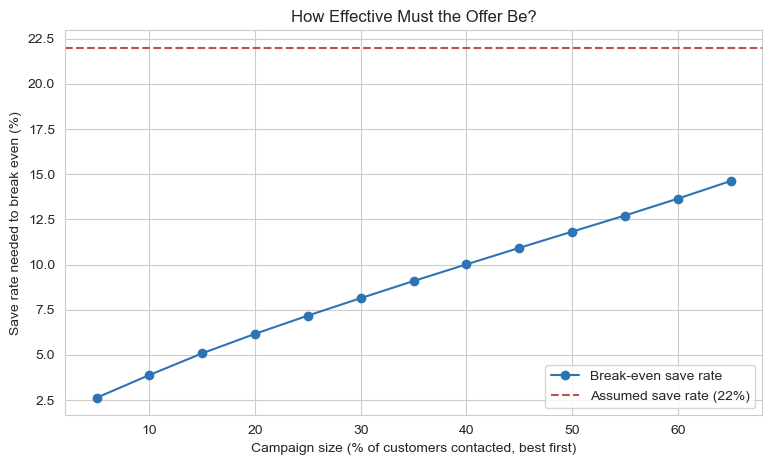

campaign size (%),5.0,10.0,15.0,20.0,25.0,30.0,35.0,40.0,45.0,50.0,55.0,60.0,65.0
break-even save rate (%),2.6,3.9,5.1,6.2,7.2,8.1,9.1,10.0,10.9,11.8,12.7,13.6,14.6


In [24]:
def breakeven_save_rate(fraction, P=BASE):
    k = int(fraction * n)
    lo, hi = 0.0, 1.0
    for _ in range(40):
        mid = (lo + hi) / 2
        N_mid = economics({**P, "save_rate": mid})[1]
        profit = np.sort(N_mid)[::-1][:k].sum()
        lo, hi = (lo, mid) if profit > 0 else (mid, hi)
    return hi

fractions = np.arange(0.05, 0.651, 0.05)
breakeven = np.array([breakeven_save_rate(f_) for f_ in fractions])

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(100 * fractions, 100 * breakeven, marker="o", color="#2E74B5", label="Break-even save rate")
ax.axhline(100 * BASE["save_rate"], color="#C0504D", linestyle="--", label=f"Assumed save rate ({BASE['save_rate']:.0%})")
ax.set_xlabel("Campaign size (% of customers contacted, best first)")
ax.set_ylabel("Save rate needed to break even (%)")
ax.set_title("How Effective Must the Offer Be?")
ax.legend()
plt.show()

pd.DataFrame({"campaign size (%)": (100 * fractions).round(0), "break-even save rate (%)": (100 * breakeven).round(1)}).set_index("campaign size (%)").T


A campaign is profitable wherever the assumed save rate sits above the curve. The margin of safety is wide under the base assumptions, but it rests on the CLV and cost inputs from Section 3, so the next section tests how fragile that conclusion is.


### 8.5 Sensitivity analysis

**One-way sensitivity:** each assumption is moved across its tested range while the others stay at base values, and the *maximum expected profit* (the profit of the best possible campaign) is recorded.


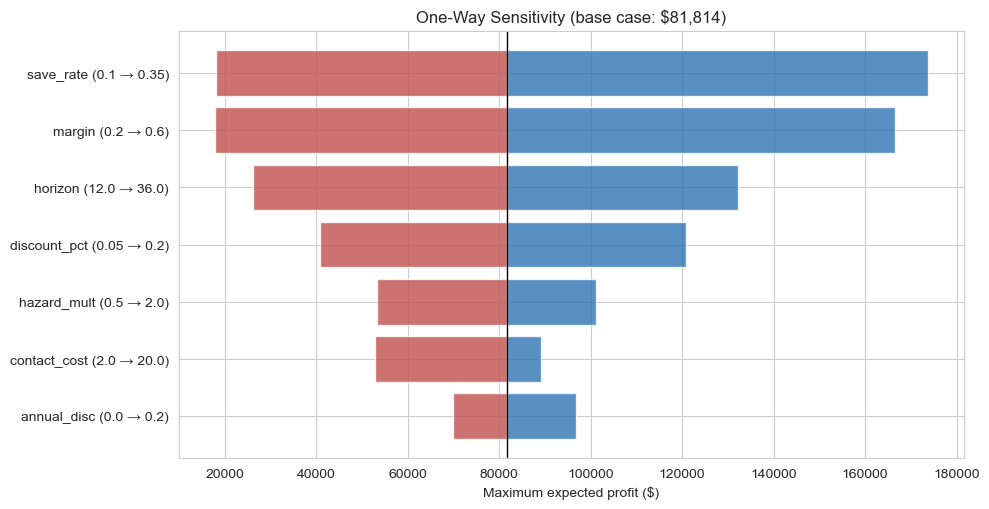

,low value,profit at low ($),high value,profit at high ($),swing ($)
assumption,,,,,
save_rate,0.10,18047.16,0.35,173737.61,155690.46
margin,0.20,17791.22,0.60,166598.83,148807.61
horizon,12.00,26230.65,36.00,132202.77,105972.12
discount_pct,0.05,120870.35,0.20,40887.29,79983.05
hazard_mult,0.50,101212.50,2.00,53388.08,47824.42
contact_cost,2.00,89190.03,20.00,52801.41,36388.62
annual_disc,0.00,96898.61,0.20,70021.94,26876.67


In [25]:
def max_profit(P):
    return np.clip(economics(P)[1], 0, None).sum()

ranges = {"margin": (0.20, 0.60), "horizon": (12, 36), "annual_disc": (0.0, 0.20), "hazard_mult": (0.5, 2.0),
          "save_rate": (0.10, 0.35), "contact_cost": (2.0, 20.0), "discount_pct": (0.05, 0.20)}
base_profit = max_profit(BASE)

rows = []
for key, (lo_v, hi_v) in ranges.items():
    lo_p, hi_p = max_profit({**BASE, key: lo_v}), max_profit({**BASE, key: hi_v})
    rows.append({"assumption": key, "low value": lo_v, "profit at low ($)": lo_p,
                 "high value": hi_v, "profit at high ($)": hi_p, "swing ($)": abs(hi_p - lo_p)})
tornado = pd.DataFrame(rows).sort_values("swing ($)").set_index("assumption")

fig, ax = plt.subplots(figsize=(10, 5.2))
for i, (key, r_) in enumerate(tornado.iterrows()):
    lo_p, hi_p = r_["profit at low ($)"], r_["profit at high ($)"]
    ax.barh(i, hi_p - base_profit, left=base_profit, color="#2E74B5" if hi_p >= base_profit else "#C0504D", alpha=0.8)
    ax.barh(i, lo_p - base_profit, left=base_profit, color="#2E74B5" if lo_p >= base_profit else "#C0504D", alpha=0.8)
ax.set_yticks(range(len(tornado)))
ax.set_yticklabels([f"{k} ({r_['low value']} \u2192 {r_['high value']})" for k, r_ in tornado.iterrows()])
ax.axvline(base_profit, color="black", linewidth=1)
ax.set_xlabel("Maximum expected profit ($)")
ax.set_title(f"One-Way Sensitivity (base case: ${base_profit:,.0f})")
plt.tight_layout()
plt.show()

tornado.sort_values("swing ($)", ascending=False).round(2)


**Two-way sensitivity:** the two quantities a retention team can least control and least know in advance, offer effectiveness (save rate) and offer generosity (discount depth), varied together.


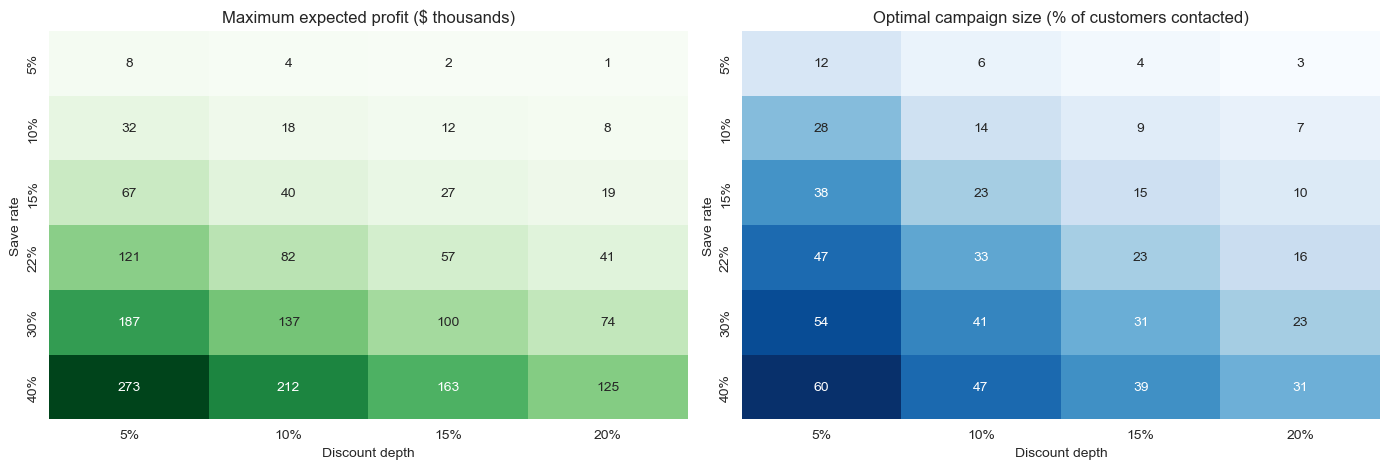

In [26]:
sr_grid = [0.05, 0.10, 0.15, 0.22, 0.30, 0.40]
dp_grid = [0.05, 0.10, 0.15, 0.20]
profit_grid = pd.DataFrame(index=[f"{int(s_ * 100)}%" for s_ in sr_grid], columns=[f"{int(d_ * 100)}%" for d_ in dp_grid], dtype=float)
share_grid = profit_grid.copy()
for s_, d_ in product(sr_grid, dp_grid):
    N_ = economics({**BASE, "save_rate": s_, "discount_pct": d_})[1]
    profit_grid.loc[f"{int(s_ * 100)}%", f"{int(d_ * 100)}%"] = np.clip(N_, 0, None).sum() / 1000
    share_grid.loc[f"{int(s_ * 100)}%", f"{int(d_ * 100)}%"] = 100 * (N_ > 0).mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
sns.heatmap(profit_grid, annot=True, fmt=".0f", cmap="Greens", cbar=False, ax=axes[0])
axes[0].set_title("Maximum expected profit ($ thousands)")
sns.heatmap(share_grid, annot=True, fmt=".0f", cmap="Blues", cbar=False, ax=axes[1])
axes[1].set_title("Optimal campaign size (% of customers contacted)")
for ax in axes:
    ax.set_xlabel("Discount depth")
    ax.set_ylabel("Save rate")
plt.tight_layout()
plt.show()


Profit varies by roughly an order of magnitude across plausible assumptions, which is why the notebook never presents a single dollar figure as a forecast. Offer effectiveness and margin are the largest drivers, and the optimal campaign *size* swings widely as well: a more effective or cheaper offer justifies reaching further down the risk ranking.

The unresolved time-scale issue from Section 3 matters but less: halving or doubling the long-run hazard moves maximum profit between roughly $101k and $53k, a factor of about two.


### 8.6 A robust contact list

A customer who is worth contacting under the base case may not be under other plausible assumptions. To identify customers whose decision does **not** depend on the exact assumptions, the economics are re-evaluated across a grid of 243 scenarios (save rate, margin, horizon, discount depth, and long-run hazard multiplier, three values each). The *robustness share* is the fraction of scenarios in which contacting the customer has positive expected value.

> The grid is a convenience set of plausible assumptions, **not a probability distribution**, so the robustness share measures *insensitivity to assumptions*, not the chance that contacting pays off.


In [27]:
scenario_axes = {"save_rate": [0.10, 0.22, 0.35], "margin": [0.25, 0.40, 0.55], "horizon": [12, 24, 36],
                 "discount_pct": [0.05, 0.10, 0.20], "hazard_mult": [0.5, 1.0, 2.0]}
scenarios = [dict(zip(scenario_axes, combo)) for combo in product(*scenario_axes.values())]
positive_counts = np.zeros(n)
for sc in scenarios:
    positive_counts += (economics({**BASE, **sc})[1] > 0)
robust_share = positive_counts / len(scenarios)

robust_class = pd.cut(robust_share, [-0.001, 0.20, 0.80, 1.001],
                      labels=["Not worthwhile", "Borderline (assumption-dependent)", "Robust contact"]).astype(str)
print(f"{len(scenarios)} scenarios evaluated\n")

summary = pd.DataFrame({"customers": pd.Series(robust_class).value_counts()})
summary["% of base"] = 100 * summary["customers"] / n
summary.loc[["Robust contact", "Borderline (assumption-dependent)", "Not worthwhile"]].round(1)


243 scenarios evaluated



,customers,% of base
Robust contact,651,9.2
Borderline (assumption-dependent),2494,35.4
Not worthwhile,3898,55.3


In [28]:
pd.crosstab(df["persona_name"], robust_class, normalize="index").mul(100).round(1)[
    ["Robust contact", "Borderline (assumption-dependent)", "Not worthwhile"]]


col_0,Robust contact,Borderline (assumption-dependent),Not worthwhile
persona_name,,,
Long-Tenure Low-Engagement,0.1,9.8,90.1
Loyal Premium,0.0,23.2,76.8
New & High-Risk,22.4,55.7,21.9
New & Price-Sensitive,14.2,49.7,36.1


In [29]:
base_contact = N > 0
print("Base-case contact decisions by robustness class:")
pd.crosstab(pd.Series(robust_class, name="robustness class"), pd.Series(np.where(base_contact, "contact", "do not contact"), name="base case"))


Base-case contact decisions by robustness class:


base case,contact,do not contact
robustness class,,
Borderline (assumption-dependent),1696,798
Not worthwhile,0,3898
Robust contact,651,0


Only 628 customers (about 9% of the base) are robust contacts, and they are concentrated in the two new-customer personas. Of the 2,359 customers the base case says to contact, about three-quarters (1,731) are **borderline**: their decision depends on the exact assumptions. The Robust group is the safest place to start a campaign. The Borderline group is where the assumptions decide the outcome and therefore where a pilot would be most informative.


## 9. Ranked Target List and Persisted Outputs

The ranked list orders customers by expected net value of contact. The recommended action is purely the **economic rule under base-case assumptions**; the robustness class shows how sensitive that recommendation is. Outputs use the out-of-fold probability, and Module 3's original score is kept alongside it for transparency. **Module 8's ROI simulator should read `churn_probability_oof`.**


In [30]:
priority_segment = (pd.Series(value_tier.astype(str)) + " x " + pd.Series(risk_tier.astype(str))).to_numpy()

target = pd.DataFrame({
    "customerID": df["customerID"].to_numpy(),
    "persona_name": df["persona_name"].to_numpy(),
    "Contract": df["Contract"].to_numpy(),
    "tenure": df["tenure"].to_numpy(),
    "MonthlyCharges": mc,
    "churn_probability_module3": p_m3,
    "churn_probability_oof": p,
    "clv_margin_horizon": V,
    "expected_value_at_risk": expected_value_at_risk,
    "break_even_probability": p_star,
    "expected_net_value_of_contact": N,
    "value_tier": value_tier.astype(str),
    "risk_tier": risk_tier.astype(str),
    "priority_segment": priority_segment,
    "recommended_action_base_case": np.where(N > 0, "Contact", "Do not contact"),
    "contact_robustness_share": robust_share,
    "contact_robustness_class": robust_class,
}).sort_values("expected_net_value_of_contact", ascending=False).reset_index(drop=True)
target.insert(0, "priority_rank", np.arange(1, n + 1))

stamp = date.today().isoformat()
target.to_parquet(FEATURE_STORE_DIR / f"telco_prioritization_{stamp}.parquet", index=False)
target.to_parquet(FEATURE_STORE_DIR / "telco_prioritization_latest.parquet", index=False)
target.round(4).to_csv(REPORTS_DIR / "retention_target_list_latest.csv", index=False)

target.head(10)[["priority_rank", "customerID", "persona_name", "MonthlyCharges", "churn_probability_oof",
                 "clv_margin_horizon", "expected_net_value_of_contact", "contact_robustness_class"]].round(3)


,priority_rank,customerID,persona_name,MonthlyCharges,churn_probability_oof,clv_margin_horizon,expected_net_value_of_contact,contact_robustness_class
0,1,5419-JPRRN,New & High-Risk,101.45,1.000,707.734,137.310,Robust contact
1,2,7216-EWTRS,New & High-Risk,100.80,1.000,703.200,136.398,Robust contact
2,3,0107-YHINA,New & High-Risk,99.75,1.000,695.875,134.925,Robust contact
3,4,0295-PPHDO,New & High-Risk,95.45,0.996,665.877,128.113,Robust contact
4,5,9497-QCMMS,New & High-Risk,93.55,1.000,652.623,126.228,Robust contact
5,6,3178-FESZO,New & High-Risk,100.25,0.951,699.363,125.875,Robust contact
6,7,4910-GMJOT,New & High-Risk,94.60,0.985,659.948,124.894,Robust contact
7,8,9300-AGZNL,New & High-Risk,94.00,0.988,655.762,124.506,Robust contact
8,9,8149-RSOUN,New & High-Risk,93.85,0.988,654.715,124.409,Robust contact
9,10,2656-TABEH,New & High-Risk,100.20,0.940,699.014,123.573,Robust contact


In [31]:
optimal = kpi_table.loc[("Net-value ranking", "profit-optimal size")]
kpi_summary = {
    "note": "Base-case figures under the assumptions in configs/roi_assumptions.json; scenario-conditional, not forecasts.",
    "created": stamp,
    "total_monthly_revenue": float(mc.sum()),
    "monthly_revenue_at_risk": float(revenue_at_risk.sum()),
    "expected_value_at_risk": float(expected_value_at_risk.sum()),
    "precision_at_top_10pct_risk": float(precision_top10),
    "base_rate_churn": float(y.mean()),
    "profit_optimal_campaign": {k: float(v) for k, v in optimal.items()},
    "profit_optimal_share_of_base_pct": float(100 * optimal["customers contacted"] / n),
    "kpis_by_budget_net_value_ranking": {
        label: {k: float(v) for k, v in kpi_table.loc[("Net-value ranking", label)].items()}
        for label in ["top 10%", "top 20%", "top 30%"]},
    "break_even_save_rate_by_campaign_size_pct": {
        f"{int(round(100 * f_))}%": float(round(100 * b_, 2)) for f_, b_ in zip(fractions, breakeven)},
    "robust_contact_customers": int((robust_class == "Robust contact").sum()),
}
with open(REPORTS_DIR / "retention_kpis_base_case.json", "w") as f:
    json.dump(kpi_summary, f, indent=2)

roi_config = {
    "status": "core business layer; assumptions are analyst-set placeholders, not measured values",
    "created": stamp,
    "base_assumptions": BASE,
    "tested_ranges": {k: list(v) for k, v in ranges.items()},
    "robustness_scenarios": scenario_axes,
    "probability_used": "out-of-fold calibrated churn probability (5-fold cross-fit; Module 3 recipe)",
    "clv_method": "persona-level constant hazard from exposure (churners / customer-months); margin basis; finite horizon; discounted",
    "contact_economics": "N = s*p*V - contact_cost - (1 - p + s*p)*D ; break-even p* = (contact_cost + D) / (s*V + (1-s)*D)",
    "persona_monthly_hazard": {k: float(v) for k, v in persona_stats["monthly_hazard"].items()},
    "time_scale_caveat": "Churn flag and tenure imply different time scales; hazard_mult tests the sensitivity.",
}
with open(CONFIGS_DIR / "roi_assumptions.json", "w") as f:
    json.dump(roi_config, f, indent=2)

print("Saved ranked target list ->", FEATURE_STORE_DIR / "telco_prioritization_latest.parquet")
print("Saved CSV for business users ->", REPORTS_DIR / "retention_target_list_latest.csv")
print("Saved KPI summary ->", REPORTS_DIR / "retention_kpis_base_case.json")
print("Saved assumptions ->", CONFIGS_DIR / "roi_assumptions.json")


Saved ranked target list -> ..\data\feature_store\telco_prioritization_latest.parquet
Saved CSV for business users -> ..\reports\retention_target_list_latest.csv
Saved KPI summary -> ..\reports\retention_kpis_base_case.json
Saved assumptions -> ..\configs\roi_assumptions.json


---
## Summary and Recommendations

**What was built:** out-of-fold churn probabilities; an exposure-based CLV with a Cox-conditional sensitivity check; revenue and value at risk; a closed-form, value-aware break-even for contacting each customer; a CLV × risk matrix; a profit-curve ROI simulator with threshold comparison, business KPIs, break-even save rates, one- and two-way sensitivity, and a 243-scenario robust contact list; and a ranked, persisted target list.

**Key findings from the executed run** (all conditional on the Section 3 assumptions)
- Out-of-fold probabilities are needed: Module 3's all-customer scores are partly in-sample and look better than they are.
- **Churn risk carries most of the commercial value.** Value- and cost-aware ranking beats risk-only ranking by only a few percent at fixed budgets (about 1% at the optimal size), and the simple `MonthlyCharges × risk` rule captures nearly all of it. Ranking by CLV alone loses money.
- **Who to target is robust to the CLV method; dollars are not.** Target lists overlap heavily across CLV methods, while methods that ignore churn hazard overstate profit by large margins.
- **Profit-based thresholds beat accuracy- and F1-based ones.** The gap is modest in the base case (F1 forgoes about 3–4% of profit, accuracy about 9%, the default 0.50 about 17%) but becomes large when offers are weak or expensive, where the F1 threshold can lose money outright.
- **Profit-maximizing is not ROI-maximizing**, and returns diminish with campaign size: ROI falls from about 2.8× at the top 10% to about 1.1× at the profit-optimal size.
- **Only about 9% of customers are robust contacts**; roughly three-quarters of the base-case contact list depends on the assumptions.
- Break-even save rates rise with campaign size, from a few percent for the top 5% of customers to roughly a tenth for the top 50%.
- Maximum profit moves by roughly an order of magnitude across plausible assumptions, with offer effectiveness and margin the largest drivers.

**How to read these results honestly**
- Every dollar figure scales with assumptions the dataset cannot supply. Use them to compare options and to see which assumptions matter, not as forecasts.
- The save rate is the single most important unknown, and only a randomized pilot (sized in Module 5) can measure it.
- The data's churn flag and tenure imply different time scales; the long-run hazard multiplier tests this, but the underlying inconsistency is a property of the dataset.

**Recommendations**
1. **Start with the Robust contact group** (Section 8.6) and run a randomized pilot on the Borderline group, where assumptions decide the outcome.
2. **Replace the placeholder assumptions** with SmartTel's real margin, offer cost, and discount terms before relying on any dollar figure.
3. **Use risk-based ranking as the default and treat CLV as a refinement and communication layer.** It explains decisions and sizes campaigns but changes who is chosen only modestly.
4. **Pick the targeting threshold by expected profit** once costs and save rates are known, rather than by accuracy or F1.

**Handoff to Module 8 (dashboard):** read `churn_probability_oof` and the assumptions in `configs/roi_assumptions.json` as slider defaults; the scenario controls (campaign budget, probability threshold, save rate, discount depth, margin) map directly onto Sections 8.1–8.5. Module 5's experimental uplift columns remain optional and are not used here.

